# Clase 8: Métricas de Evaluación en Escenarios Desbalanceados

### Machine Learning (RIA-805) — Bloque 2 — Factibilidad Técnico-Financiera

**Docente:** Marco Capio  
**Fecha:** Semana 4

**Objetivo:** Comprender por qué el accuracy es engañoso en datasets desbalanceados, calcular métricas apropiadas (matriz de confusión, precision, recall, F1, ROC-AUC, PR-AUC) e interpretar correctamente el rendimiento de un modelo en escenarios reales.

**Conexión con la práctica:** En P2 aplicarán estas métricas a su modelo de Wall-Following y aprenderán a traducir errores a costos en dólares.

## ¿Dónde estamos?

En la **Clase 7** evaluamos la factibilidad técnica y la pertinencia de los modelos. Hoy profundizamos en uno de los criterios centrales de rendimiento: cómo medir un clasificador cuando las clases están desbalanceadas. En estas situaciones, la clase que más nos interesa suele ser mucho menos frecuente que las demás.

> **Pregunta guía:** ¿Qué pasa si el 95% de los datos son de una clase y el 5% de otra? ¿El accuracy sigue siendo confiable?

## ¿Qué es el desbalance de clases?

Existe **desbalance de clases** cuando las categorías de la variable objetivo aparecen con frecuencias muy distintas. La clase más frecuente se llama **mayoritaria** y la menos frecuente, **minoritaria** o **positiva** cuando representa el evento que queremos detectar.

Como guía aproximada —los límites dependen del problema— podemos hablar de desbalance **leve** (hasta 1:2), **moderado** (entre 1:2 y 1:10), **severo** (entre 1:10 y 1:100) y **extremo** (más allá de 1:100). La razón por sí sola no determina qué métrica usar: también importan las consecuencias de cada error.

**Ejemplos reales:** fraude (pocas transacciones fraudulentas), churn o abandono (una fracción de clientes se va), enfermedad (casos positivos poco frecuentes) y fallas de sensores (la mayor parte del tiempo el equipo funciona normalmente).

Un modelo entrenado con datos desbalanceados puede aprender a predecir siempre la clase mayoritaria. Así obtiene un accuracy alto, pero es inútil para detectar la clase que importa. Por eso debemos observar otras métricas y los tipos de error.

## Matriz de confusión

La **matriz de confusión** compara la clase real con la clase predicha. En este notebook, la clase positiva es `rice` y la clase negativa es `no rice`.

| | Predicción positiva: rice | Predicción negativa: no rice |
|---|---:|---:|
| **Real positiva: rice** | **TP** — verdaderos positivos: rice detectados | **FN** — falsos negativos: rice que no detectamos |
| **Real negativa: no rice** | **FP** — falsos positivos: falsas alarmas de rice | **TN** — verdaderos negativos: no rice correctamente descartados |

La matriz de confusión es la base para calcular todas las métricas de clasificación. Nos permite distinguir entre aciertos y errores de distinta naturaleza.

In [1]:
%matplotlib inline

import os
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, RobustScaler

# Mantener un estilo coherente y legible en todos los gráficos de la clase.
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

# Buscar la raíz del proyecto desde la carpeta actual o cualquiera de sus padres.
# Esto permite ejecutar el notebook tanto desde la raíz como desde notebooks/.
PROJECT_ROOT = next(
    (
        candidate
        for candidate in (Path.cwd(), *Path.cwd().parents)
        if (candidate / "data" / "processed" / "crop.parquet").exists()
    ),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "No se encontró data/processed/crop.parquet. "
        "Ejecuta el notebook desde una carpeta dentro del repositorio."
    )

DATA_PATH = PROJECT_ROOT / "data" / "processed" / "crop.parquet"
REPORTS_DIR = PROJECT_ROOT / "reports"
FIGURES_DIR = REPORTS_DIR / "figures"
REPORTS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

print(f"Raíz del proyecto: {PROJECT_ROOT}")
print(f"Dataset: {DATA_PATH}")
print(f"Figuras y reportes: {REPORTS_DIR}")

Raíz del proyecto: c:\Users\lenovo\OneDrive\UCACUE\MACHIENE LEARNING\GITHUB PROYECTOS\ml-demo1-profesor
Dataset: c:\Users\lenovo\OneDrive\UCACUE\MACHIENE LEARNING\GITHUB PROYECTOS\ml-demo1-profesor\data\processed\crop.parquet
Figuras y reportes: c:\Users\lenovo\OneDrive\UCACUE\MACHIENE LEARNING\GITHUB PROYECTOS\ml-demo1-profesor\reports


## Crear un problema binario desbalanceado

Para esta clase transformaremos **Crop Recommendation** en un problema binario: predecir si el cultivo recomendado es **`rice` (positivo)** o **cualquier otro cultivo (negativo)**. En el dataset, `rice` representa aproximadamente el 4.5% de las observaciones.

Hacemos esta transformación con datos que ya conocemos para concentrarnos en la evaluación: la variable objetivo queda muy poco frecuente y podremos ver de forma concreta por qué una métrica global puede ocultar el desempeño en la clase minoritaria. No cambiaremos las etiquetas originales; crearemos una nueva variable binaria.

In [2]:
# Cargar los datos procesados y verificar las columnas que necesita el ejercicio.
df = pd.read_parquet(DATA_PATH)
if "label" not in df.columns:
    raise KeyError("El dataset debe contener la columna 'label'.")

# rice es la clase positiva (1); todos los demás cultivos son la clase negativa (0).
df["target_binario"] = (df["label"] == "rice").astype(int)
conteos = df["target_binario"].value_counts().sort_index()
porcentajes = df["target_binario"].value_counts(normalize=True).sort_index() * 100
print("Distribución de la variable objetivo:")
print(
    pd.DataFrame(
        {
            "clase": ["no rice", "rice"],
            "observaciones": [conteos.get(0, 0), conteos.get(1, 0)],
            "porcentaje": [porcentajes.get(0, 0.0), porcentajes.get(1, 0.0)],
        }
    ).to_string(index=False, formatters={"porcentaje": "{:.2f}%".format})
)

# Excluir la etiqueta original para evitar filtrar la respuesta al modelo.
X = df.drop(columns=["label", "target_binario"])
y = df["target_binario"]
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42,
)

# Ajustar el escalador solo con train evita filtrar información del conjunto de prueba.
scaler = RobustScaler()
X_train_scaled = pd.DataFrame(
    scaler.fit_transform(X_train), columns=X_train.columns, index=X_train.index
)
X_test_scaled = pd.DataFrame(
    scaler.transform(X_test), columns=X_test.columns, index=X_test.index
)

print(f"\nEntrenamiento: {X_train_scaled.shape[0]} filas")
print(f"Prueba: {X_test_scaled.shape[0]} filas")
print(f"Rice en prueba: {int(y_test.sum())} de {len(y_test)}")

Distribución de la variable objetivo:
  clase  observaciones porcentaje
no rice           2100     95.45%
   rice            100      4.55%

Entrenamiento: 1760 filas
Prueba: 440 filas
Rice en prueba: 20 de 440


## El modelo «tramposo»

Primero construiremos un clasificador trivial: predice siempre la clase mayoritaria, **no rice**. No aprende patrones ni usa las características; sirve como referencia para ver qué resultado se puede obtener simplemente ignorando todos los positivos. Muchos modelos con datos desbalanceados pueden acercarse a esta conducta.

In [3]:
# El clasificador trivial asigna 0 (no rice) a cada observación de prueba.
y_pred_trivial = np.zeros(len(y_test), dtype=int)
accuracy_trivial = accuracy_score(y_test, y_pred_trivial)
precision_trivial = precision_score(y_test, y_pred_trivial, zero_division=0)
recall_trivial = recall_score(y_test, y_pred_trivial, zero_division=0)
f1_trivial = f1_score(y_test, y_pred_trivial, zero_division=0)
cm_trivial = confusion_matrix(y_test, y_pred_trivial, labels=[0, 1])

print(f"Accuracy:  {accuracy_trivial:.3f}")
print(f"Precision: {precision_trivial:.3f}")
print(f"Recall:    {recall_trivial:.3f}")
print(f"F1:        {f1_trivial:.3f}")
print("\nMatriz de confusión (filas = real; columnas = predicción):")
print(cm_trivial)
print("\nAccuracy alto, pero recall = 0. El modelo es inútil para detectar rice.")

Accuracy:  0.955
Precision: 0.000
Recall:    0.000
F1:        0.000

Matriz de confusión (filas = real; columnas = predicción):
[[420   0]
 [ 20   0]]

Accuracy alto, pero recall = 0. El modelo es inútil para detectar rice.


## La trampa del accuracy

En este dataset hay 100 ejemplos `rice` entre 2,200 observaciones. Un modelo que siempre responde «no rice» obtiene **95.45% de accuracy** en el conjunto completo, aunque detecta **0% de los positivos**. En el conjunto de prueba estratificado el valor será muy parecido.

¿Es útil? No: no identifica ningún caso de `rice`. El accuracy solo cuenta la proporción total de aciertos y puede quedar dominado por la clase mayoritaria.

> **Conclusión:** nunca reportes solo accuracy en datasets desbalanceados. Acompáñalo con métricas de la clase de interés y la matriz de confusión.

## Entrenar un modelo real

Ahora entrenaremos un **Random Forest** con las características del dataset. Compararemos sus métricas con el modelo trivial para observar si logra detectar `rice` y qué tipos de error comete. Mantendremos la división de entrenamiento y prueba para que ambos modelos se evalúen sobre los mismos ejemplos.

In [4]:
# Entrenar Random Forest sobre las variables escaladas del conjunto de entrenamiento.
modelo_rf = RandomForestClassifier(n_estimators=100, random_state=42)
modelo_rf.fit(X_train_scaled, y_train)
y_pred_rf = modelo_rf.predict(X_test_scaled)
y_proba_rf = modelo_rf.predict_proba(X_test_scaled)[:, 1]

accuracy_rf = accuracy_score(y_test, y_pred_rf)
precision_rf = precision_score(y_test, y_pred_rf, zero_division=0)
recall_rf = recall_score(y_test, y_pred_rf, zero_division=0)
f1_rf = f1_score(y_test, y_pred_rf, zero_division=0)
cm_rf = confusion_matrix(y_test, y_pred_rf, labels=[0, 1])

print(f"Accuracy:  {accuracy_rf:.3f}")
print(f"Precision: {precision_rf:.3f}")
print(f"Recall:    {recall_rf:.3f}")
print(f"F1:        {f1_rf:.3f}")
print("\nMatriz de confusión (filas = real; columnas = predicción):")
print(cm_rf)
print("\nReporte de clasificación:")
print(
    classification_report(
        y_test,
        y_pred_rf,
        labels=[0, 1],
        target_names=["no rice", "rice"],
        zero_division=0,
    )
)
print(f"Recall de rice mayor que cero: {recall_rf > 0}.")

Accuracy:  0.995
Precision: 1.000
Recall:    0.900
F1:        0.947

Matriz de confusión (filas = real; columnas = predicción):
[[420   0]
 [  2  18]]

Reporte de clasificación:
              precision    recall  f1-score   support

     no rice       1.00      1.00      1.00       420
        rice       1.00      0.90      0.95        20

    accuracy                           1.00       440
   macro avg       1.00      0.95      0.97       440
weighted avg       1.00      1.00      1.00       440

Recall de rice mayor que cero: True.


## Visualizar la matriz de confusión

La matriz de confusión permite ver cuántos **TP**, **TN**, **FP** y **FN** tiene el modelo. Cada celda corresponde a un tipo de acierto o error. Revisar estos conteos ayuda a entender qué significa una métrica agregada en términos de predicciones concretas.

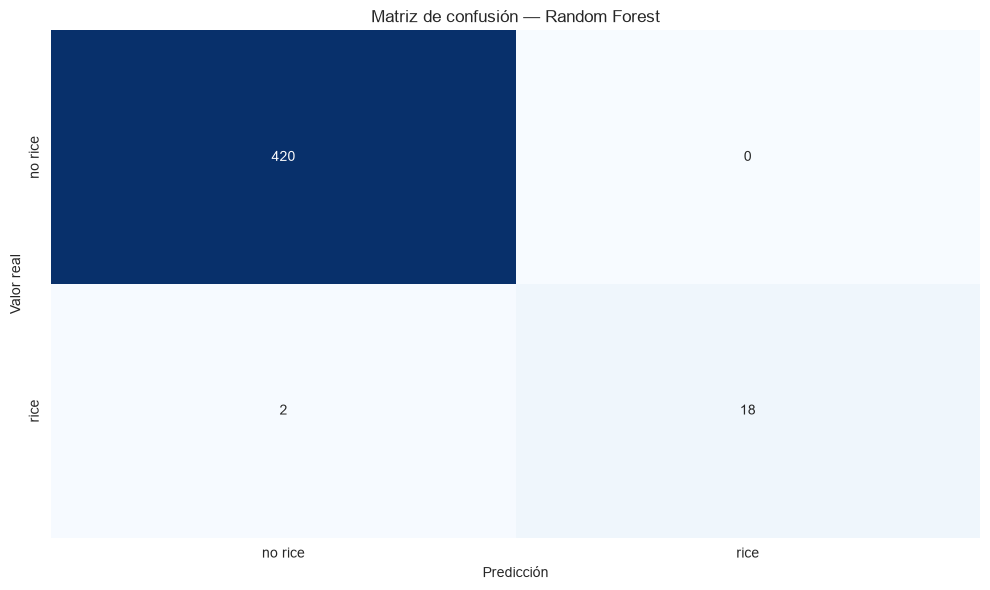

TP=18 (rice detectados), TN=420 (no rice correctos), FP=0 (falsas alarmas), FN=2 (rice perdidos).


In [5]:
# Etiquetas en orden: no rice (0), rice (1); filas reales y columnas predichas.
fig, ax = plt.subplots()
sns.heatmap(
    cm_rf,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=False,
    xticklabels=["no rice", "rice"],
    yticklabels=["no rice", "rice"],
    ax=ax,
)
ax.set_title("Matriz de confusión — Random Forest")
ax.set_xlabel("Predicción")
ax.set_ylabel("Valor real")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "cm_rf_binario.png", dpi=150, bbox_inches="tight")
plt.show()

# En una matriz con labels=[0, 1], los índices son TN, FP / FN, TP.
tn, fp, fn, tp = cm_rf.ravel()
print(
    f"TP={tp} (rice detectados), TN={tn} (no rice correctos), "
    f"FP={fp} (falsas alarmas), FN={fn} (rice perdidos)."
)

## Precision, Recall y F1

- **Precision** = TP / (TP + FP). De todos los casos que predije como `rice`, ¿cuántos eran realmente `rice`? Una precision alta implica menos falsas alarmas.
- **Recall** = TP / (TP + FN). De todos los `rice` reales, ¿cuántos detecté? Un recall alto implica menos positivos perdidos.
- **F1** = 2 × (precision × recall) / (precision + recall). Es la media armónica de precision y recall; disminuye si una de las dos es baja.

¿Cuál importa más? Depende del costo de los errores: evitar falsos negativos puede exigir recall, mientras que reducir falsas alarmas puede exigir precision. En la **Clase 9** veremos cómo traducir esos errores a costos.

In [6]:
# Mostrar el reporte completo para ambas clases.
print(
    classification_report(
        y_test,
        y_pred_rf,
        labels=[0, 1],
        target_names=["no rice", "rice"],
        zero_division=0,
    )
)

# Extraer las métricas por clase para comparar explícitamente el rendimiento.
precision_no_rice = precision_score(y_test, y_pred_rf, pos_label=0, zero_division=0)
recall_no_rice = recall_score(y_test, y_pred_rf, pos_label=0, zero_division=0)
f1_no_rice = f1_score(y_test, y_pred_rf, pos_label=0, zero_division=0)
precision_rice = precision_score(y_test, y_pred_rf, pos_label=1, zero_division=0)
recall_rice = recall_score(y_test, y_pred_rf, pos_label=1, zero_division=0)
f1_rice = f1_score(y_test, y_pred_rf, pos_label=1, zero_division=0)

print("Métricas por clase:")
print(f"no rice — precision: {precision_no_rice:.3f}, recall: {recall_no_rice:.3f}, F1: {f1_no_rice:.3f}")
print(f"rice    — precision: {precision_rice:.3f}, recall: {recall_rice:.3f}, F1: {f1_rice:.3f}")
print("Compara las métricas de rice con las de no rice: una métrica promedio puede ocultar esta diferencia.")

              precision    recall  f1-score   support

     no rice       1.00      1.00      1.00       420
        rice       1.00      0.90      0.95        20

    accuracy                           1.00       440
   macro avg       1.00      0.95      0.97       440
weighted avg       1.00      1.00      1.00       440

Métricas por clase:
no rice — precision: 0.995, recall: 1.000, F1: 0.998
rice    — precision: 1.000, recall: 0.900, F1: 0.947
Compara las métricas de rice con las de no rice: una métrica promedio puede ocultar esta diferencia.


## Curva ROC

La **curva ROC** evalúa al modelo en todos los umbrales posibles. En el eje vertical representa la tasa de verdaderos positivos (**TPR**, equivalente al recall); en el horizontal, la tasa de falsos positivos (**FPR**). Cada punto corresponde a una decisión distinta sobre qué probabilidad mínima basta para predecir la clase positiva.

El área bajo la curva (**ROC-AUC**) resume la capacidad de ordenar positivos por encima de negativos: **0.5** equivale a un ordenamiento aleatorio y **1.0** a uno perfecto. Un AUC mayor que **0.9** suele considerarse excelente como orientación, pero no es una regla universal ni reemplaza la evaluación del contexto. En desbalance, también revisaremos la curva Precision-Recall.

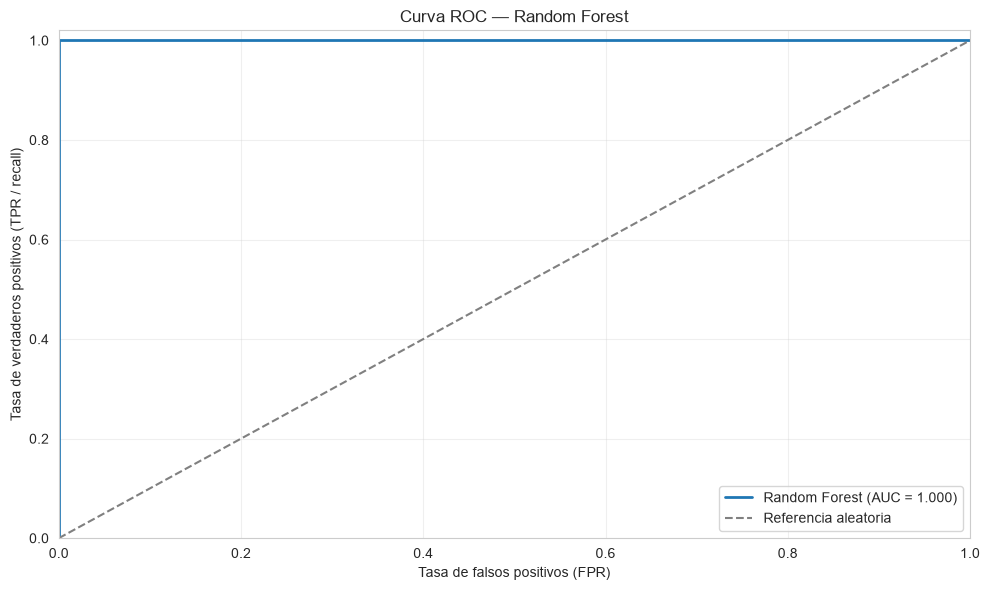

ROC-AUC: 1.0000


In [7]:
# Usar las probabilidades de la clase positiva para evaluar distintos umbrales.
fpr, tpr, umbrales_roc = roc_curve(y_test, y_proba_rf)
roc_auc_rf = roc_auc_score(y_test, y_proba_rf)

fig, ax = plt.subplots()
ax.plot(fpr, tpr, color="#1f77b4", lw=2, label=f"Random Forest (AUC = {roc_auc_rf:.3f})")
ax.plot([0, 1], [0, 1], color="gray", lw=1.5, linestyle="--", label="Referencia aleatoria")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)
ax.set_xlabel("Tasa de falsos positivos (FPR)")
ax.set_ylabel("Tasa de verdaderos positivos (TPR / recall)")
ax.set_title("Curva ROC — Random Forest")
ax.legend(loc="lower right")
ax.grid(True, alpha=0.3)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "roc_rf_binario.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"ROC-AUC: {roc_auc_rf:.4f}")

## Curva Precision-Recall

Con desbalance severo, la curva ROC puede parecer demasiado optimista: la FPR divide los falsos positivos entre todos los negativos, y hay muchos negativos disponibles. La curva **Precision-Recall (PR)** es más informativa cuando la clase positiva es rara porque muestra directamente el compromiso entre precision y recall.

El **Average Precision (AP)** resume la curva Precision-Recall en un número: combina precision a distintos niveles de recall, ponderando por el cambio en recall. Como referencia, un clasificador sin capacidad de ordenar casos suele tener AP cercano a la prevalencia de la clase positiva.

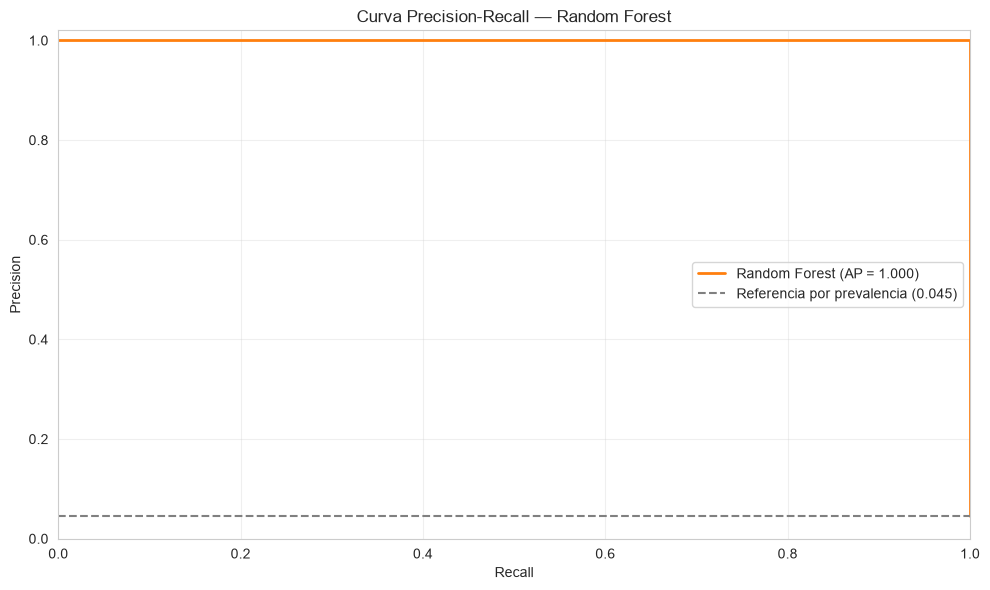

Average Precision (AP / PR-AUC): 1.0000
Prevalencia de rice en prueba (referencia): 0.0455


In [8]:
# Calcular precision y recall para distintos umbrales y resumirlos con AP.
precision_curve_rf, recall_curve_rf, umbrales_pr = precision_recall_curve(y_test, y_proba_rf)
ap_rf = average_precision_score(y_test, y_proba_rf)
prevalencia_test = float(np.mean(y_test))

fig, ax = plt.subplots()
ax.plot(
    recall_curve_rf,
    precision_curve_rf,
    color="#ff7f0e",
    lw=2,
    label=f"Random Forest (AP = {ap_rf:.3f})",
)
ax.axhline(
    prevalencia_test,
    color="gray",
    lw=1.5,
    linestyle="--",
    label=f"Referencia por prevalencia ({prevalencia_test:.3f})",
)
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_title("Curva Precision-Recall — Random Forest")
ax.legend(loc="best")
ax.grid(True, alpha=0.3)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "pr_rf_binario.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"Average Precision (AP / PR-AUC): {ap_rf:.4f}")
print(f"Prevalencia de rice en prueba (referencia): {prevalencia_test:.4f}")

## Comparar métricas

La siguiente tabla reúne el **modelo trivial** y el **Random Forest**. Comparamos accuracy, precision, recall, F1, ROC-AUC y PR-AUC (Average Precision). Observa que cada métrica responde una pregunta distinta: un único número no describe todos los errores ni el desempeño sobre la clase minoritaria.

Para el modelo trivial, todas las probabilidades se fijan en cero. ROC-AUC es 0.5 porque todos los casos reciben la misma puntuación; el Average Precision resulta igual a la prevalencia de la clase positiva. Estos valores permiten comparar con el nivel de referencia.

In [9]:
# Comparar ambos modelos en los mismos datos de prueba y guardar el reporte.
y_proba_trivial = np.zeros(len(y_test), dtype=float)
comparacion = pd.DataFrame(
    [
        {
            "modelo": "Trivial (siempre no rice)",
            "accuracy": accuracy_trivial,
            "precision": precision_trivial,
            "recall": recall_trivial,
            "f1": f1_trivial,
            "roc_auc": roc_auc_score(y_test, y_proba_trivial),
            "pr_auc_ap": average_precision_score(y_test, y_proba_trivial),
        },
        {
            "modelo": "Random Forest",
            "accuracy": accuracy_rf,
            "precision": precision_rf,
            "recall": recall_rf,
            "f1": f1_rf,
            "roc_auc": roc_auc_rf,
            "pr_auc_ap": ap_rf,
        },
    ]
)
print(comparacion.to_string(index=False, float_format=lambda valor: f"{valor:.4f}"))

ruta_comparacion = REPORTS_DIR / "comparacion_metricas_binario.csv"
comparacion.to_csv(ruta_comparacion, index=False)
print(f"\nTabla guardada en: {ruta_comparacion}")

                   modelo  accuracy  precision  recall     f1  roc_auc  pr_auc_ap
Trivial (siempre no rice)    0.9545     0.0000  0.0000 0.0000   0.5000     0.0455
            Random Forest    0.9955     1.0000  0.9000 0.9474   1.0000     1.0000

Tabla guardada en: c:\Users\lenovo\OneDrive\UCACUE\MACHIENE LEARNING\GITHUB PROYECTOS\ml-demo1-profesor\reports\comparacion_metricas_binario.csv


## ¿Qué métrica usar?

| Contexto o prioridad | Métrica que conviene priorizar | Pregunta que responde |
|---|---|---|
| No perder casos positivos de alto riesgo | **Recall** | ¿Qué proporción de los positivos reales detectamos? |
| Las falsas alarmas son costosas | **Precision** | ¿Qué proporción de las alertas positivas era correcta? |
| Balancear precision y recall | **F1** | ¿Cómo se comportan juntas ambas métricas? |
| Comparar la capacidad de ranking entre umbrales | **ROC-AUC** | ¿El modelo ordena positivos antes que negativos? |
| Positivos muy raros y foco en alertas positivas | **PR-AUC / Average Precision** | ¿Qué precision se conserva al aumentar recall? |
| Clases equilibradas y errores de costo similar | **Accuracy** junto con otras métricas | ¿Qué proporción total de predicciones fue correcta? |

> **Regla de oro:** nunca uses solo accuracy en un problema desbalanceado. Define primero qué error es más importante y reporta métricas de la clase positiva junto con la matriz de confusión.

## Conexión con la Clase 9

Las métricas nos dicen cómo rinde el modelo, pero no cuánto cuesta equivocarse. En la próxima clase veremos cómo traducir **FP** y **FN** a dólares para tomar decisiones económicas: una falsa alarma puede activar una revisión innecesaria y un positivo perdido puede representar una oportunidad o un riesgo no atendido.

La métrica prioritaria depende del valor de esos costos y del umbral de decisión; no existe una respuesta única para todos los problemas.

## Conclusiones

1. **El accuracy puede engañar:** un modelo que siempre predice la clase mayoritaria puede parecer preciso y no detectar ningún positivo.
2. **La matriz de confusión es la base:** muestra verdaderos y falsos positivos y negativos, antes de resumirlos en métricas.
3. **Precision y recall reflejan compromisos distintos:** la primera controla falsas alarmas; el segundo, positivos perdidos. F1 equilibra ambos.
4. **ROC y PR no son intercambiables:** ROC-AUC resume ranking entre clases; PR-AUC / AP suele informar mejor cuando la clase positiva es rara.
5. **La métrica se elige según el contexto:** define qué errores importan y no reportes una sola métrica aislada.

**Próxima clase:** matriz de costos económicos para convertir los errores del modelo en decisiones y costos monetarios.

In [10]:
print("Clase 8 completada. Revisa reports/figures/ y reports/comparacion_metricas_binario.csv")

Clase 8 completada. Revisa reports/figures/ y reports/comparacion_metricas_binario.csv
